# Multi-Branch Model - Huấn luyện mô hình đa nhánh

---

Mục tiêu là xây dựng một mô hình đa nhánh, đầu vào là `RBG` và đi vào cách nhánh với mỗi nhánh nhận một đặc điểm của ảnh và vai trò khác nhau nhằm trích xuất ra đặc trưng tốt nhât dể gộp vào lớp cuối cùng và phân loại ra `real` và `spoof`.

In [1]:
import os
import sys
import math
import pandas as pd
import numpy as np
from pathlib import Path

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0' 

import tensorflow as tf
from keras.models import load_model, Sequential
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation, RandomContrast, RandomBrightness
from keras.optimizers import AdamW
from keras.optimizers.schedules import CosineDecay
from keras.losses import BinaryFocalCrossentropy
from keras.callbacks import EarlyStopping
from keras.utils import set_random_seed, image_dataset_from_directory
from sklearn.metrics import classification_report

sys.path.append(os.path.abspath('..'))
from models.MultiBranchModel import multibranch_model
from src.evaluate import MetricsCallback, plot_training_history, evaluate_model, calculate_metrics

I0000 00:00:1791841268.152018   44778 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
IMG_SIZE = 224
EPOCHS = 30
LR_WARMUP_EPOCHS = 2
BATCH_SIZE = 32
SEED = 42
DATA_DIR = Path('../datasets/LCC_FASD')
OUTPUT_DIR = Path('../outputs/multibranch-model')
CACHE_DIR = Path('../cache/multibranch-model')

set_random_seed(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chuẩn bị dữ liệu

---

In [3]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomTranslation(0.1, 0.1, interpolation='nearest'),
    RandomRotation(factor=0.015, interpolation='nearest'),
    RandomContrast(factor=0.2),
    RandomBrightness(factor=0.1),
])

E0000 00:00:1791841271.018856   44778 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
train_dir = DATA_DIR / 'train'
val_dir = DATA_DIR / 'val'
test_dir = DATA_DIR / 'test'

print("Tập Train:")
train_ds_raw = image_dataset_from_directory(
    train_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

print("\nTập Validation:")
val_ds_raw = image_dataset_from_directory(
    val_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("\nTập Test:")
test_ds_raw = image_dataset_from_directory(
    test_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("Class:", train_ds_raw.class_names)

Tập Train:
Found 8299 files belonging to 2 classes.

Tập Validation:
Found 2948 files belonging to 2 classes.

Tập Test:
Found 7580 files belonging to 2 classes.
Class: ['real', 'spoof']


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
to_uint8 = lambda x, y: (tf.cast(tf.round(x), tf.uint8), y)
to_float = lambda x, y: (tf.cast(x, tf.float32), y)
augment  = lambda x, y: (data_augmentation(tf.cast(x, tf.float32), training=True), y)

def make_cached(ds, path=None):
    ds = ds.map(to_uint8)
    ds = ds.cache(str(path)) if path else ds.cache()
    for _ in ds:
        pass
    return ds

train_c = make_cached(train_ds_raw)                      
val_c   = make_cached(val_ds_raw)                       
test_c  = make_cached(test_ds_raw, CACHE_DIR / 'test') 

train_ds = (train_c.shuffle(2000, seed=SEED).batch(BATCH_SIZE).map(augment, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
val_ds  = val_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)
test_ds = test_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)

In [6]:
labels = ["real", "spoof"]
real_counts = len(os.listdir(train_dir / "real"))
spoof_counts = len(os.listdir(train_dir / "spoof"))

total_counts = real_counts + spoof_counts
print(f"Tổng số lượng ảnh: {total_counts}")

class_weights = {0: total_counts / (2 * real_counts), 1: total_counts / (2 * spoof_counts)}
print(f"Class weights: {class_weights}")

Tổng số lượng ảnh: 8299
Class weights: {0: 3.392886345053148, 1: 0.5864188807235726}


## 2. Khởi tạo mô hình

---

Mô hình được xây dựng trong [MultiBranchModel](../models/MultiBranchModel.py)

In [7]:
input_shape = (IMG_SIZE, IMG_SIZE, 3)

model = multibranch_model(input_shape=input_shape, num_classes=1)
model.build((None, IMG_SIZE, IMG_SIZE, 3))
model.summary()

Model: "multibranch_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 224, 224,  │          0 │ rgb_input[0][0]   │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ color_channels      │ (None, 224, 224,  │          0 │ rescale[0][0]     │
│ (Lambda)            │ 9)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ noise_channels      │ (None, 224, 224,  │          0 │ rescale[0][0]     │
│ (Lambda)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ edge_channels       │ (None, 224, 224,  │          0 │ rescale[0][0]     │
│ (Lambda)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │         36 │ color_channels[0… │
│ (BatchNormalizatio… │ 9)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │         12 │ noise_channels[0… │
│ (BatchNormalizatio… │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │         12 │ edge_channels[0]… │
│ (BatchNormalizatio… │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │      1,296 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │        432 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │        432 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │         64 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat

 Total params: 1,356,129 (5.17 MB)

 Trainable params: 1,342,529 (5.12 MB)

 Non-trainable params: 13,600 (53.12 KB)

In [8]:
callbacks = [
    MetricsCallback(
        val_dataset=val_ds, 
        save_dir=OUTPUT_DIR
    ),

    EarlyStopping(
        monitor='val_acer', 
        patience=8,
        mode='min',
        restore_best_weights=True,
        verbose=1
    )
]

steps_per_epoch = math.ceil(len(train_ds_raw) / BATCH_SIZE)
warmup_steps = LR_WARMUP_EPOCHS * steps_per_epoch

lr_schedule = CosineDecay(
    initial_learning_rate=0.000363 / 100,
    warmup_target=0.000363,
    warmup_steps=warmup_steps,
    decay_steps=EPOCHS * steps_per_epoch - warmup_steps,
)

In [9]:
model.compile(
    optimizer=AdamW(learning_rate=lr_schedule, weight_decay=2e-3),
    loss=BinaryFocalCrossentropy(gamma=2.0),
    metrics=["accuracy"],
)

## 3. Huấn luyện mô hình

---

In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/30


/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 746ms/step - accuracy: 0.5393 - loss: 1.1415 - APCER: 41.92% - BPCER: 41.73% - ACER: 41.82% (t*: 0.4466) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 267s 929ms/step - accuracy: 0.5393 - loss: 1.1415 - val_accuracy: 0.1374 - val_loss: 0.2262 - val_apcer: 0.4192 - val_bpcer: 0.4173 - val_acer: 0.4182
Epoch 2/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 788ms/step - accuracy: 0.5516 - loss: 0.1923 - APCER: 30.24% - BPCER: 30.37% - ACER: 30.31% (t*: 0.4927) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 253s 971ms/step - accuracy: 0.5516 - loss: 0.1923 - val_accuracy: 0.2890 - val_loss: 0.1761 - val_apcer: 0.3024 - val_bpcer: 0.3037 - val_acer: 0.3031
Epoch 3/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 827ms/step - accuracy: 0.6014 - loss: 0.1657 - APCER: 26.43% - BPCER: 26.42% - ACER: 26.42% (t*: 0.4792) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 265s 1s/step - accuracy: 0.6014 - loss: 0.1657 - val_accuracy: 0.6917 - val_loss: 0.1317 - val_apcer: 0.2643 - val_bpcer: 0.2642 - val_acer: 0.26

## 4. Đánh giá kết quả 

---

In [11]:
model = load_model(OUTPUT_DIR / 'best_model.keras', compile=False)
threshold_best = float(open(OUTPUT_DIR / 'best_threshold.txt').read())
print(f"Ngưỡng tốt nhất: {threshold_best}")

y_prob = model.predict(test_ds).flatten()
y_pred = (y_prob >= threshold_best).astype(int)

y_true_list = []
for images, labels in test_ds:
    y_true_list.append(labels.numpy())
y_true = np.concatenate(y_true_list)

print(classification_report(y_true, y_pred))

Ngưỡng tốt nhất: 0.48678967356681824
237/237 ━━━━━━━━━━━━━━━━━━━━ 61s 252ms/step
              precision    recall  f1-score   support

         0.0       0.24      0.84      0.38       314
         1.0       0.99      0.89      0.94      7266

    accuracy                           0.89      7580
   macro avg       0.62      0.86      0.66      7580
weighted avg       0.96      0.89      0.91      7580



In [12]:
report = calculate_metrics(y_true.flatten(), y_prob, threshold_best)

metrics = pd.DataFrame([{
    "Model": "MultiBranchModel", 
    "Threshold": threshold_best, 
    **report
}])
metrics

,Model,Threshold,EER (%),APCER (%),BPCER (%),ACER (%),AUC (%),ACC (%)
0,MultiBranchModel,0.48679,14.012739,11.285439,16.242038,13.763739,91.754963,88.509235


Đã lưu biểu đồ tại: ../outputs/multibranch-model/training_history.png


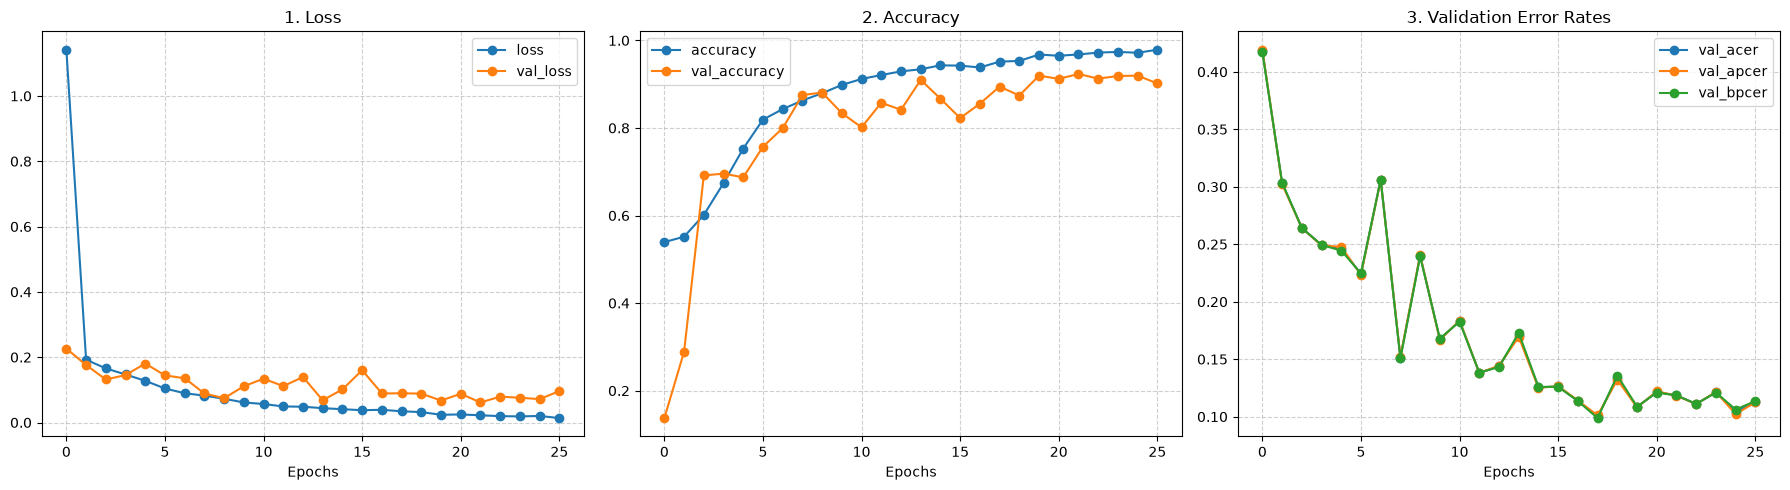

In [13]:
plot_training_history(history.history, output=str(OUTPUT_DIR / 'training_history.png'))

93/93 ━━━━━━━━━━━━━━━━━━━━ 22s 242ms/step
Đã lưu biểu đồ tại: ../outputs/multibranch-model/evaluation_report.png


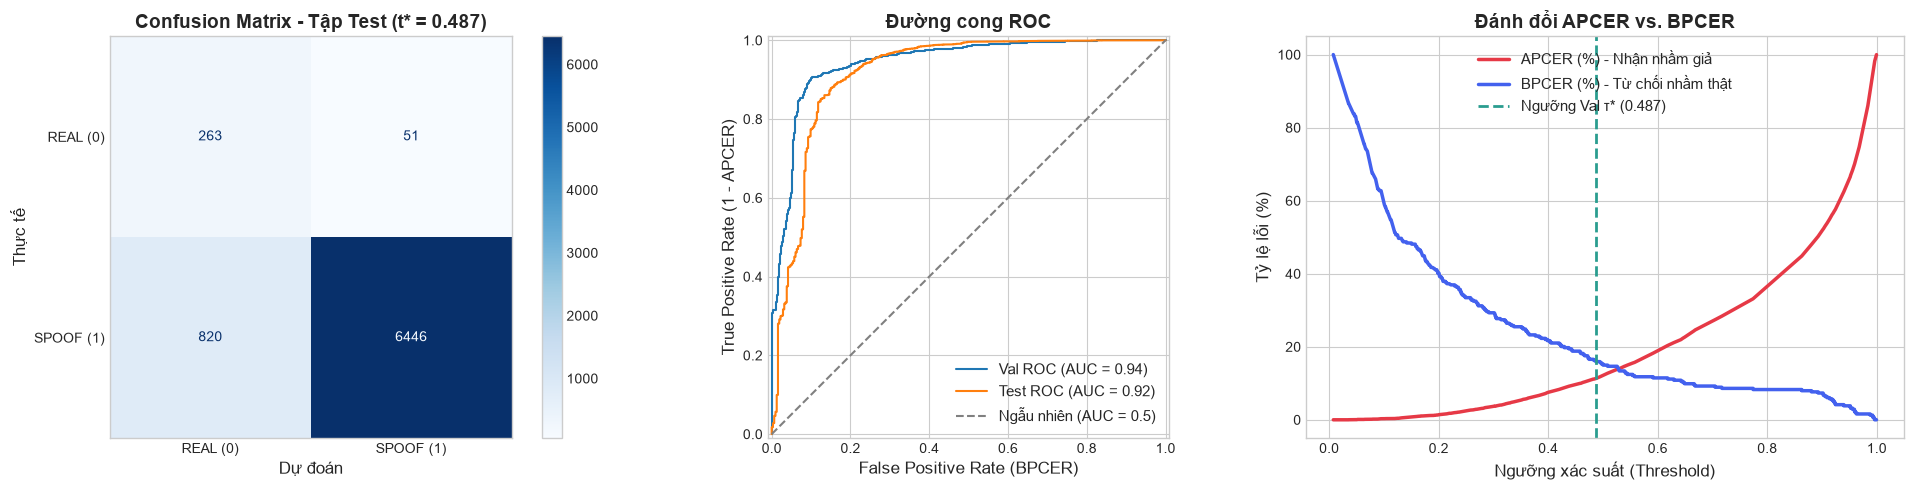

In [14]:
y_val_prob = model.predict(val_ds).flatten()

y_val_list = []
for images, labels in val_ds:
    y_val_list.append(labels.numpy())
y_val_true = np.concatenate(y_val_list)

evaluate_model((y_true, y_prob), (y_val_true, y_val_prob), threshold_best, output=str(OUTPUT_DIR / 'evaluation_report.png'))